In [ ]:
import networkx as nx
import random
from tqdm import tqdm

def barabasi_albert_graph(n, m, seed=None):
    if seed is not None:
        random.seed(seed)

    if m < 1 or m >= n:
        raise ValueError("Require 1 ≤ m < n")

    G = nx.Graph()

    # --- Seed graph ---
    if m == 1:
        G.add_node(0)
        node_list = [0]
        start = 1
    else:
        G.add_nodes_from(range(m))
        for i in range(m):
            for j in range(i + 1, m):
                G.add_edge(i, j)

        node_list = []
        for i in range(m):
            node_list.extend([i] * (m - 1))
        start = m

    # --- Preferential attachment ---
    for new_node in range(start, n):
        targets = set()
        while len(targets) < m:
            targets.add(random.choice(node_list))

        for t in targets:
            G.add_edge(new_node, t)
            node_list.append(t)
            node_list.append(new_node)

    return G


In [2]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def dfs_spanning_tree(G, root=0):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend, weighted=False):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    # G.add_nodes_from(list(range(backend.num_qubits)))
    if weighted:
        # props = backend.properties()
        # # Extract two-qubit gate errors
        # for gate in props.gates:
        #     if gate.gate in ['cz', 'cx', 'ecr']:
        #         q1, q2 = gate.qubits
        #         err = next(param.value for param in gate.parameters if param.name == "gate_error")
        #         if err<1.0:
        #             G.add_edge(q1, q2, weight=1-err)

        props = backend.properties()
        conf = backend.configuration()
        coupling = conf.coupling_map

        alpha=0.75
        beta_readout=0.7
        beta_t12=0.2
        beta_gate=0.1

        G = nx.Graph()
        # G.add_nodes_from(range(conf.num_qubits))

        # ---- Node (1Q) noise ----
        node_noise = {}
        for q in range(conf.num_qubits):
            qb = props.qubits[q]
            for p in qb:
                if p.name=='T1':
                    if p.value>0:
                        t1 = p.value
                    else:
                        t1 = 100e6
                if p.name=='T2':
                    if p.value>0:
                        t2 = p.value
                    else:
                        t2 = 100e6
                if p.name=='readout_error':
                    readout_err = p.value
            decoh = (1 / t1 + 1 / t2) if t1 > 0 and t2 > 0 else 0
            gate_errs = [
                param.value
                for g in props.gates
                if len(g.qubits) == 1 and g.qubits[0] == q
                for param in g.parameters
                if param.name == "gate_error"
            ]
            # print(gate_errs)
            max_gate_err = np.mean(gate_errs) if gate_errs else 0
            node_noise[q] = (
                beta_readout * readout_err
                + beta_t12 * decoh
                + beta_gate * max_gate_err
            )
            # print(q, node_noise[q])
            G.add_node(q, weight=max(1 - node_noise[q], 0))
            # print(q, decoh, max_gate_err, readout_err, 1-node_noise[q])

        # ---- Edge (2Q) noise ----
        for g in props.gates:
            if len(g.qubits) == 2:
                q1, q2 = g.qubits
                err = next(param.value for param in g.parameters if param.name == "gate_error")
                node_term = (node_noise[q1] + node_noise[q2]) / 2
                # print(node_term)
                combined_noise = alpha * err + (1 - alpha) * node_term
                reliability = 1 - combined_noise
                # if reliability>0.9:
                G.add_edge(q1, q2, weight=max(reliability, 0))
    else:
        G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

def graph_fiedler_sort(graph):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def graph_laplacian_embedding(G, k=2, alpha=0.95, normalized=False):
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        if normalized:
            A = adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            degrees = np.sum(A, axis=1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degrees, 1e-12)))

            # --- Normalized Laplacian ---
            L_sym = np.eye(G.number_of_nodes()) - D_inv_sqrt @ A @ D_inv_sqrt

            # --- Compute eigenvalues and eigenvectors ---
            vals, vecs = eigh(L_sym)
            # Sort eigenpairs
            idx = np.argsort(vals)
            vals, vecs = vals[idx], vecs[:, idx]

            # Skip the first eigenvector (constant)
            X = vecs[:, 1:k+1]
        else:
            adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            L = laplacian(adj_matrix)
            vals, vecs = eigh(L)
            X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None
    
import matplotlib.pyplot as plt
def gradient_graph(graph : nx.Graph, normalized=False, tree=None, title=None, flip_sign=False):
    if not tree:
        tree = graph
    G = nx.Graph()
    G.add_nodes_from(sorted(graph.nodes()))
    G.add_edges_from(graph.edges())
    graph=G
    fiedler = graph_laplacian_embedding(tree, k=1, normalized=normalized).flatten()
    # sorted_nodes = np.argsort(fiedler)

    fiedler_dict = {}
    fiedler_dict = {list(graph.nodes)[i] : (1+2*flip_sign*(-1))*fiedler[i] for i in range(graph.number_of_nodes())}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()


def selective_bfs(G, source, n, weight='weight', threshold=0.9, relax_factor=0.5, min_threshold=0.0):
    if source not in G:
        raise ValueError(f"Source node {source} not in graph")

    visited = set([source])
    q = deque([source])
    sub_nodes = [source]
    current_threshold = threshold

    while len(sub_nodes) < n:
        progress = False
        temp_q = deque(q)

        while temp_q and len(sub_nodes) < n:
            u = temp_q.popleft()
            for v in G.neighbors(u):
                if v not in visited:
                    w = G[u][v].get(weight, 1.0)
                    if w >= current_threshold:
                        visited.add(v)
                        q.append(v)
                        sub_nodes.append(v)
                        progress = True
                        if len(sub_nodes) >= n:
                            break

        # If no new nodes were added, relax the threshold
        if not progress:
            current_threshold *= relax_factor
            if current_threshold < min_threshold:
                # As a last resort, include any remaining nodes
                remaining = [v for v in G.nodes if v not in visited]
                sub_nodes.extend(remaining[: n - len(sub_nodes)])
                break

    return G.subgraph(sub_nodes).copy()

def extract_low_noise_subgraph(
    backend,
    n_target,
    beta_readout=0.75,
    beta_t12=0.2,
    beta_gate=0.1,
    start_percentile=0.90,
    relax_step=0.05,
    min_percentile=0.01,
):
    """
    Extract a low-noise connected subgraph using statistical filtering.
    
    Nodes/edges are selected by percentile thresholds rather than fixed values.
    """

    props = backend.properties()
    conf = backend.configuration()

    G = nx.Graph()

    # ---- Compute node reliability ----
    for q in range(conf.num_qubits):
        qb = props.qubits[q]
        readout_err = qb[2].value
        t1 = qb[0].value if qb[0].value > 0 else np.inf
        t2 = qb[1].value if qb[1].value > 0 else np.inf
        decoherence_term = (1.0 / t1 + 1.0 / t2)

        gate_errs = [
            param.value
            for g in props.gates if len(g.qubits) == 1 and g.qubits[0] == q
            for param in g.parameters if param.name == "gate_error"
        ]
        avg_gate_err = np.mean(gate_errs) if gate_errs else 0.0

        node_noise = (
            beta_readout * readout_err +
            beta_t12 * decoherence_term +
            beta_gate * avg_gate_err
        )
        # print(readout_err, decoherence_term, avg_gate_err)

        reliability = max(1 - node_noise, 0)
        G.add_node(q, reliability=reliability)

    # ---- Compute edge reliability ----
    for g in props.gates:
        if len(g.qubits) == 2:
            q1, q2 = g.qubits
            err_2q = next(param.value for param in g.parameters if param.name == "gate_error")
            reliability = max(1 - err_2q, 0)
            G.add_edge(q1, q2, reliability=reliability)

    # ---- Iterative percentile relaxation ----
    percentile = start_percentile

    # Compute statistical thresholds
    node_vals = np.array([d["reliability"] for _, d in G.nodes(data=True)])
    edge_vals = np.array([d["reliability"] for _, _, d in G.edges(data=True)])
    while percentile >= min_percentile:
        node_thresh = np.quantile(node_vals, percentile)
        edge_thresh = np.quantile(edge_vals, percentile)
        # print(percentile, len([x for x in edge_vals if x>edge_thresh])/len(edge_vals))

        # Filter nodes
        good_nodes = [q for q in G.nodes if G.nodes[q]["reliability"] >= node_thresh]
        G1 = G.subgraph(good_nodes).copy()

        # Filter edges
        good_edges = [(u, v) for u, v in G1.edges
                      if G1[u][v]["reliability"] >= edge_thresh]

        G2 = nx.Graph()
        G2.add_nodes_from(G1.nodes(data=True))
        G2.add_edges_from([(u, v, G1[u][v]) for u, v in good_edges])
        # draw_graph_custom(G2)

        # Connected components
        components = sorted(nx.connected_components(G2), key=len, reverse=True)
        for comp in components:
            # print(len(comp), comp)
            if len(comp) >= n_target:
                # print(f"Selected percentile: {percentile:.2f}")
                return G2.subgraph(comp).copy()

        # Relax if no valid component
        percentile -= relax_step

    return None

def central_node(G):
    # Compute eccentricity of each node
    ecc = nx.eccentricity(G)
    
    # Find center nodes (min eccentricity)
    min_ecc = min(ecc.values())
    center_nodes = [n for n, e in ecc.items() if e == min_ecc]
    
    # If multiple centers exist, break ties using closeness centrality
    if len(center_nodes) > 1:
        closeness = nx.closeness_centrality(G)
        center_nodes.sort(key=lambda n: closeness[n], reverse=True)
    
    return center_nodes[0]  # Best root

def initial_layout(graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None, noise_aware=False, na_method='selective_bfs'):
    num_nodes = graph.number_of_nodes()
    n = int(np.sqrt(num_nodes))
    if how=='fiedler':
        sorted_nodes = graph_fiedler_sort(graph)

        if topology=='chain':
            chain = find_linear_chain(backend, num_nodes)
        else:
            if noise_aware:
                if na_method=='selective_bfs':
                    G = get_coupling_graph(backend, weighted=True)
                else:
                    G = extract_low_noise_subgraph(backend, n_target=num_nodes)
            else:
                G = get_coupling_graph(backend)
            if not root_on_backend:
                root_on_backend = central_node(G)
            
            if noise_aware and na_method=='selective_bfs':
                tree_layout = selective_bfs(G, source=root_on_backend, n=num_nodes)
            else:
                tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)

            order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))

    if how not in ['trivial', 'random']:
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit

In [3]:
def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai',
                      node_size=100, font_size=6, highlight_nodes=None, title=None):
    import math

    graph = nx.Graph()
    graph.add_nodes_from(G.nodes())
    graph.add_edges_from(G.edges())
    G=graph

    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout with bottom-to-top rows
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        rows = math.ceil(n / side)
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    # Node colors
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size,
            font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

In [4]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import numpy as np

def optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=None):
    """
    Find optimal mapping between logical and physical qubits
    using Hungarian algorithm on Euclidean distances.

    Args:
        logical_embedding: np.ndarray, shape (n, k)
        physical_embedding: np.ndarray, shape (n, k)

    Returns:
        mapping: dict {logical_index: physical_index}
    """
    if not nodes:
        nodes = list(range(physical_embedding.shape[0]))
    # cost matrix: pairwise distances between embeddings
    cost_matrix = cdist(logical_embedding, physical_embedding, metric='sqeuclidean')

    # Hungarian (linear sum assignment)
    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    # Construct mapping
    mapping = {int(r): int(nodes[c]) for r, c in zip(row_ind, col_ind)}
    return mapping


In [5]:
def normalized_graph(graph:nx.Graph):
    for u,v in list(graph.edges):
        graph[u][v]['weight'] = 1.0/np.sqrt(graph.degree(u)*graph.degree(v))
    return graph

In [6]:
def return_ops(backend, graph_type='reg', param=4, average_over=5, node_list=list(range(10,101,2)), reps=2, tech='1D', k=2, topology='tree_dfs', opt_level=3, op_name='ecr', use_custom=True, stop_after_routing=False, normalize_laplacian=False, noise_aware=False, na_method='selective_bfs'):
    swaps = {'means': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]},
             'stddevs': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':[], 'fied':[], 'triv':[], 'rand':[]}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = barabasi_albert_graph(n=n, m=param, seed=0)
        gen = gen_QAOA_circuit(graph, reps=reps)
        spec_graph=graph
        if noise_aware:
            H = get_coupling_graph(backend, weighted=True)
            high_degree_nodes = [u for u in H.nodes if H.degree(u) >= 3]
            root_on_backend = max(high_degree_nodes, key=lambda q: H.nodes[q]["weight"])
        else:
            root_on_backend = backend.number_of_qubits // 2
        if tech=='1D':
            tree = dfs_spanning_tree(graph, root=0)
            
            proposed_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology, noise_aware=noise_aware, na_method=na_method, root_on_backend=root_on_backend)
        elif tech=='2D':
            logical_embedding = graph_laplacian_embedding(spec_graph, k=k, normalized=normalize_laplacian)
            logical_embedding = logical_embedding[:, :k]

            if noise_aware:
                if na_method=='selective_bfs':
                    G = get_coupling_graph(backend, weighted=True)
                else:
                    G = extract_low_noise_subgraph(backend, n_target=n)
            else:
                G = get_coupling_graph(backend)
            
            if noise_aware and na_method=='selective_bfs':
                S = selective_bfs(G, source=root_on_backend, n=n)
            else:
                S = build_tree_cluster(G, source=root_on_backend, n=n)
            physical_embedding = graph_laplacian_embedding(S, k=k)

            # if k>2:
            #     num_extra_cols = k - 2
            #     physical_embedding = np.hstack([physical_embedding, np.zeros((physical_embedding.shape[0], num_extra_cols))])

            proposed_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, proposed_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        # swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial')
        # swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(graph, backend=backend, how='random')
        # swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            swap_avg['fied'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=proposed_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['triv'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['sabre'].append(func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0))
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['means']['SABRE'].append(np.mean(swap_avg['sabre']))
        swaps['stddevs']['SABRE'].append(np.std(swap_avg['sabre']))

        swaps['means']['Proposed'].append(np.mean(swap_avg['fied']))
        swaps['stddevs']['Proposed'].append(np.std(swap_avg['fied']))

        swaps['means']['Trivial'].append(np.mean(swap_avg['triv']))
        swaps['stddevs']['Trivial'].append(np.std(swap_avg['triv']))

    return swaps

In [7]:
import warnings
warnings.filterwarnings("ignore")

# Combined Graphs

In [8]:
def return_ops_all_methods(
    backend,
    graph_type='reg',
    param=4,
    average_over=5,
    node_list=list(range(10,101,2)),
    k_list=[2,3,5],
    reps=2,
    topology='tree_dfs',
    opt_level=1,
    op_name='ecr',
    use_custom=True,
    stop_after_routing=False,
    normalize_laplacian=True,
    noise_aware=False,
    na_method='selective_bfs'
):
    methods = ["SABRE", "Trivial", "FOM"]
    for k in k_list:
        methods.append(f"SAM{k}")
    
    swaps = {
        'means': {m: [] for m in methods},
        'stddevs': {m: [] for m in methods}
    }

    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {m: [] for m in methods}

        # Generate problem graph
        if graph_type == 'reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = barabasi_albert_graph(n=n, m=param, seed=0)

        # Create QAOA circuit (unmapped)
        gen = gen_QAOA_circuit(graph, reps=reps)

        # Trivial and Random Mappings
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial')
        
        # SABRE handled separately
        sabre_mapping = None  # Automatic by SABRE transpiler

        # ====================
        # Mapping Strategy 1: Fiedler Ordered Mapping
        # ====================
        if noise_aware:
            G = get_coupling_graph(backend, weighted=True)
            high_degree_nodes = [u for u in G.nodes if G.degree(u) >= 3]
            root_on_backend = max(high_degree_nodes, key=lambda q: G.nodes[q]["weight"])
        else:
            G = get_coupling_graph(backend)
            root_on_backend = backend.num_qubits // 2
        tree = dfs_spanning_tree(graph, root=0)
        fiedler_mapping = initial_layout(tree, backend=backend, how='fiedler',
                                         topology=topology, noise_aware=noise_aware,
                                         na_method=na_method, root_on_backend=root_on_backend)

        # ====================
        # Mapping Strategies 2–4: Spectral Assignment Mapping (k = 2,3,5)
        # ====================
        logical_embeddings = {
            k: graph_laplacian_embedding(graph, k=k, normalized=normalize_laplacian)[:, :k]
            for k in k_list
        }

        # Hardware subgraph (noise-aware or standard)
        if noise_aware and na_method != 'selective_bfs':
                G = extract_low_noise_subgraph(backend, n_target=n)

        if noise_aware and na_method == 'selective_bfs':
            S = selective_bfs(G, source=root_on_backend, n=n)
        else:
            S = build_tree_cluster(G, source=root_on_backend, n=n)

        physical_embeddings = {
            k: graph_laplacian_embedding(S, k=k) for k in k_list
        }
        
        assign_mappings = {
            f"SAM{k}": optimal_qubit_assignment(logical_embeddings[k],
                                                  physical_embeddings[k],
                                                  nodes=sorted(S.nodes()))
            for k in k_list
        }

        # ===========================
        # Circuit Execution & Counting
        # ===========================
        if stop_after_routing:
            exec_map_func = custom_routed_circuit
            exec_sabre_func = sabre_routed_circuit
        else:
            exec_map_func = final_optimized_circuit
            exec_sabre_func = final_optimized_circuit

        for i in range(average_over):
            # Fiedler
            swap_avg['FOM'].append(
                exec_map_func(custom_qaoa_ansatz(graph, fiedler_mapping, backend.coupling_map, reps=reps) if use_custom else gen, 
                              backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0)
            )
        
            # Assign2 / Assign3 / Assign5
            for k in k_list:
                key = f"SAM{k}"
                swap_avg[key].append(
                    exec_map_func(circuit=custom_qaoa_ansatz(graph, assign_mappings[f"SAM{k}"], backend.coupling_map, reps=reps) if use_custom else gen, 
                                  backend=backend, initial_mapping=assign_mappings[f"SAM{k}"], opt_level=opt_level).count_ops().get(op_name, 0)
                )

            # Trivial
            swap_avg['Trivial'].append(
                exec_map_func(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0)
            )

            # SABRE
            swap_avg['SABRE'].append(
                exec_sabre_func(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0)
            )

        # ===========================
        # Statistical Results
        # ===========================
        for m in methods:
            key = m
            swaps['means'][m].append(np.mean(swap_avg[key]))
            swaps['stddevs'][m].append(np.std(swap_avg[key]))

    return swaps


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Methods returned by return_ops_all_methods()

# Colors for consistency across plots
colors = {
    "SABRE":   "#E69F00",
    "Trivial": "#56B4E9",
    "FOM": "#009E73",
    "SAM2": "#0072B2",
    "SAM3": "#D55E00",
    'SAM5': "#F0E442",
    "SAM4": "#CC79A7"
}

def plot_swap_results(swaps_dict, node_list, k_list, params, zoom=None, title_prefix="", ylabel="SWAP Count"):
    """
    swaps_dict: swap statistics returned from return_ops_all_methods()
    node_list: list of graph sizes tested (x-axis)
    params: list of values used for graph param (ex: degrees or m attachments)
    """
    methods = ["SABRE", "Trivial", "FOM"]
    for k in k_list:
        methods.append(f"SAM{k}")
    if zoom:
        node_list=node_list[:zoom]
    for param in params:
        plt.figure(figsize=(9, 6))
        
        for method in methods:
            means=swaps_dict[param]['means'][method]
            stds=swaps_dict[param]['stddevs'][method]
            if zoom:
                means=means[:zoom]
                stds=stds[:zoom]
            mean_vals = np.array(means)
            std_vals  = np.array(stds)
            
            plt.plot(node_list, mean_vals,
                     label=method,
                     color=colors.get(method, None),
                     linewidth=2)

            plt.fill_between(node_list,
                             mean_vals - std_vals,
                             mean_vals + std_vals,
                             alpha=0.25,
                             color=colors.get(method, None))

        plt.xlabel("Number of Nodes", fontsize=18)
        plt.ylabel(ylabel, fontsize=18)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)

        if title_prefix:
            plt.title(f"{title_prefix} (param = {param})", fontsize=18)

        plt.grid(alpha=0.3)
        plt.legend(fontsize=14)
        plt.tight_layout()
        plt.show()


In [10]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane, FakeSherbrooke, FakeCusco, FakeKawasaki, FakeKyiv, FakeKyoto, FakeOsaka, FakeQuebec, FakeWashingtonV2, FakeMarrakesh

In [22]:
import numpy as np

def compute_percentage_improvement(swaps_dict, methods, baseline="SABRE"):
    """
    Compute percentage improvement over a baseline method.

    Parameters
    ----------
    swaps_dict : dict
        Output of return_ops_all_methods() for a single param
    methods : list
        Methods to compare against baseline (e.g. ["FOM", "SAM2", "SAM3"])
    baseline : str
        Baseline method name (default: "SABRE")

    Returns
    -------
    improvements : dict
        {
            method: {
                'means': [...],
                'stddevs': [...]
            }
        }
    """
    improvements = {}

    sabre_means = np.array(swaps_dict['means'][baseline])
    sabre_stds  = np.array(swaps_dict['stddevs'][baseline])

    for method in methods:
        m_means = np.array(swaps_dict['means'][method])
        m_stds  = np.array(swaps_dict['stddevs'][method])

        # Percentage improvement
        perc_mean = 100.0 * (sabre_means - m_means) / sabre_means

        # Error propagation (first-order approximation)
        perc_std = 100.0 * np.sqrt(
            (m_stds / sabre_means)**2 +
            (m_means * sabre_stds / sabre_means**2)**2
        )

        improvements[method] = {
            'means': perc_mean.tolist(),
            'stddevs': perc_std.tolist()
        }

    return improvements

def compute_all_improvements(swaps_all_params, k_list, baseline="SABRE"):
    """
    Compute improvements over SABRE for all params.

    Returns
    -------
    improvements_all : dict
        {
            param: {
                method: {'means': [...], 'stddevs': [...]}
            }
        }
    """
    methods = ["FOM"] + [f"SAM{k}" for k in k_list]

    improvements_all = {}
    for param, swaps_dict in swaps_all_params.items():
        improvements_all[param] = compute_percentage_improvement(
            swaps_dict,
            methods=methods,
            baseline=baseline
        )

    return improvements_all

def plot_percentage_improvements(
    improvements_all,
    node_list,
    k_list,
    params,
    zoom=None,
    ylabel="Improvement over SABRE (%)",
    title_prefix=""
):
    methods = ["FOM"] + [f"SAM{k}" for k in k_list]

    if zoom:
        node_list = node_list[:zoom]

    for param in params:
        plt.figure(figsize=(9, 6))

        for method in methods:
            means = improvements_all[param][method]['means']
            stds  = improvements_all[param][method]['stddevs']

            if zoom:
                means = means[:zoom]
                stds  = stds[:zoom]

            means = np.array(means)
            stds  = np.array(stds)

            plt.plot(
                node_list,
                means,
                label=method,
                color=colors.get(method, None),
                linewidth=2
            )

            plt.fill_between(
                node_list,
                means - stds,
                means + stds,
                alpha=0.25,
                color=colors.get(method, None)
            )

        plt.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)

        plt.xlabel("Number of Nodes", fontsize=18)
        plt.ylabel(ylabel, fontsize=18)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)

        if title_prefix:
            plt.title(f"{title_prefix} (param = {param})", fontsize=18)

        plt.grid(alpha=0.3)
        plt.legend(fontsize=14)
        plt.tight_layout()
        plt.show()



## SWAP COUNTS

## FakeMarrakesh

In [11]:
backend = FakeMarrakesh()

In [12]:
import matplotlib.pyplot as plt

nodes_reg = list(range(10, 101, 2))
params_reg = list(range(3,9,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops_all_methods(backend, graph_type='reg', param=param,
                         average_over=10, node_list=nodes_reg, k_list=[2,3,4],
                         topology='tree_dfs', op_name='swap', use_custom=True, reps=1, noise_aware=True, stop_after_routing=True)

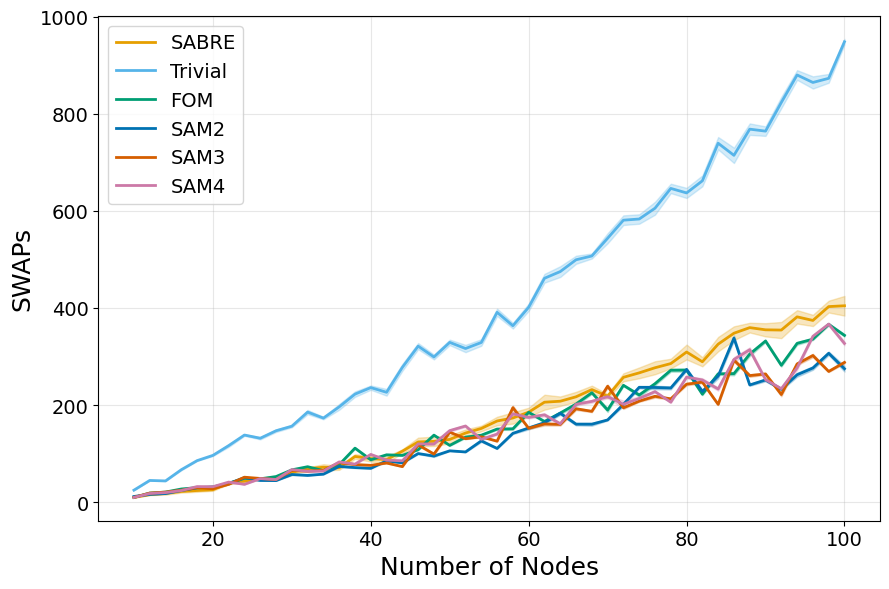

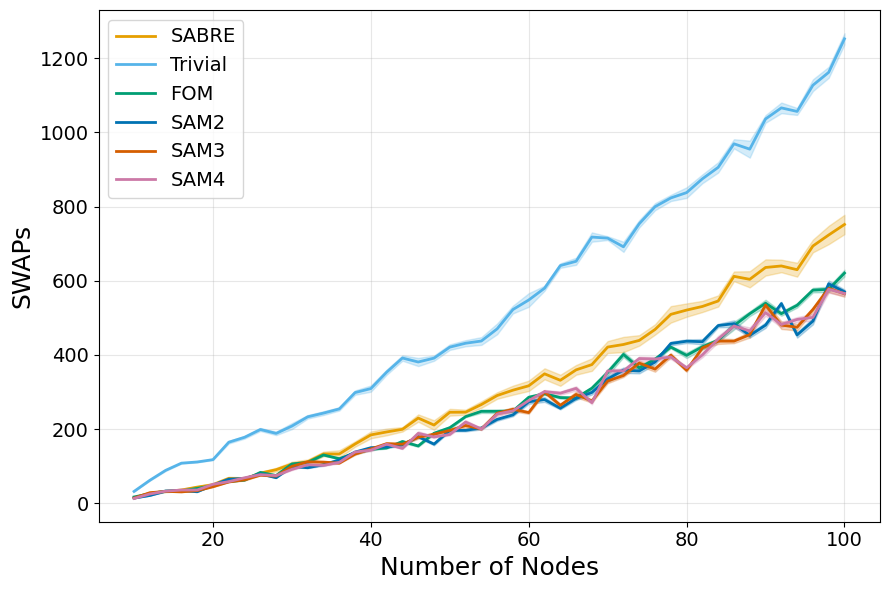

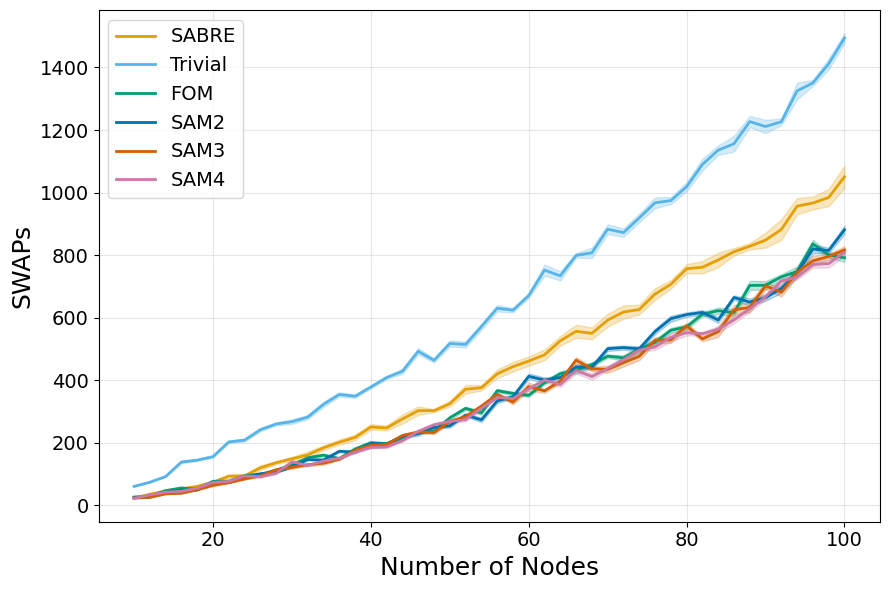

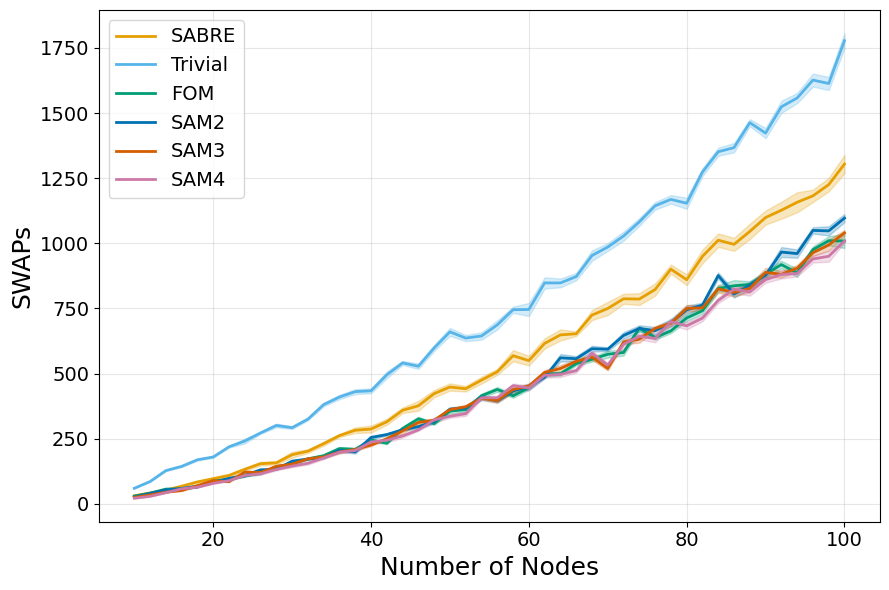

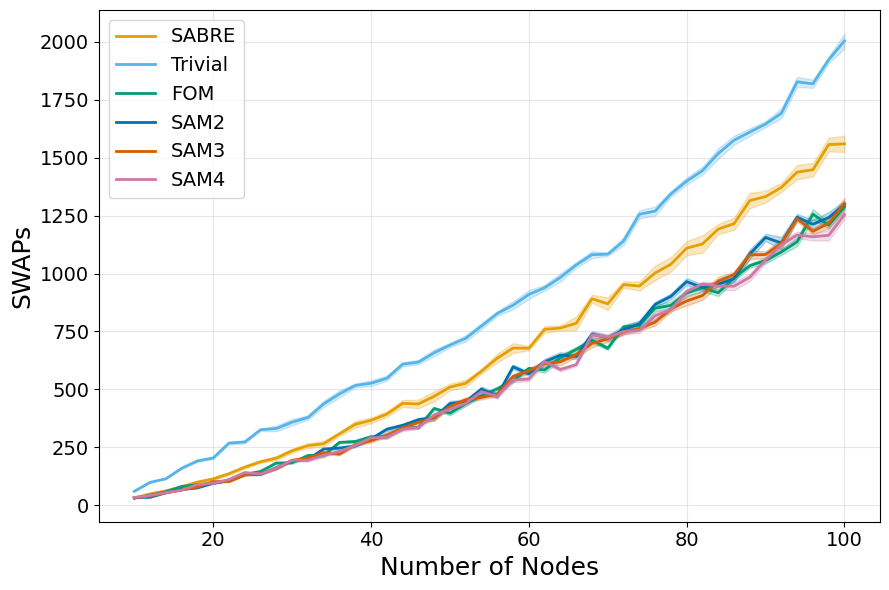

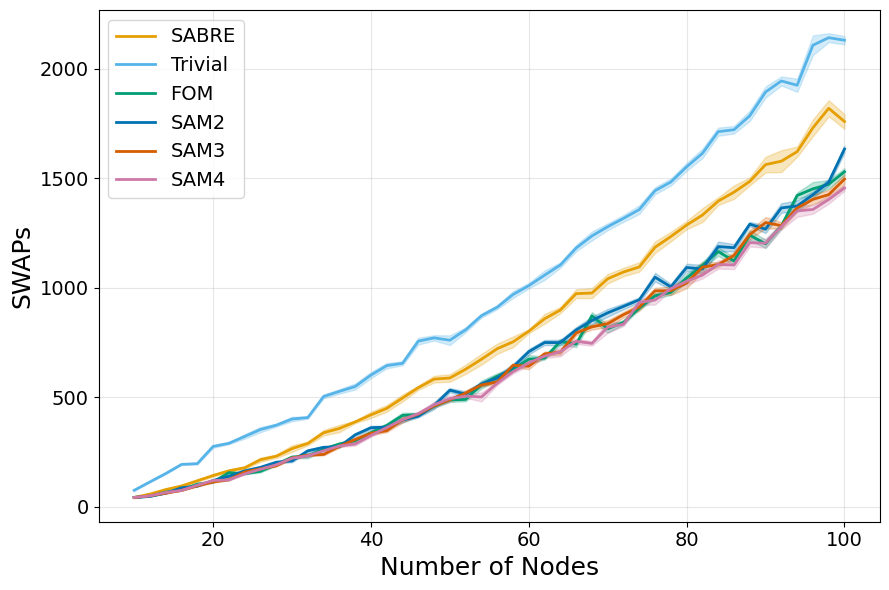

In [13]:
plot_swap_results(swaps_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="SWAPs")

In [14]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops_all_methods(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba, k_list=[2,3,4],
                         topology='tree_dfs', op_name='swap', use_custom=True, reps=1, noise_aware=True, stop_after_routing=True)

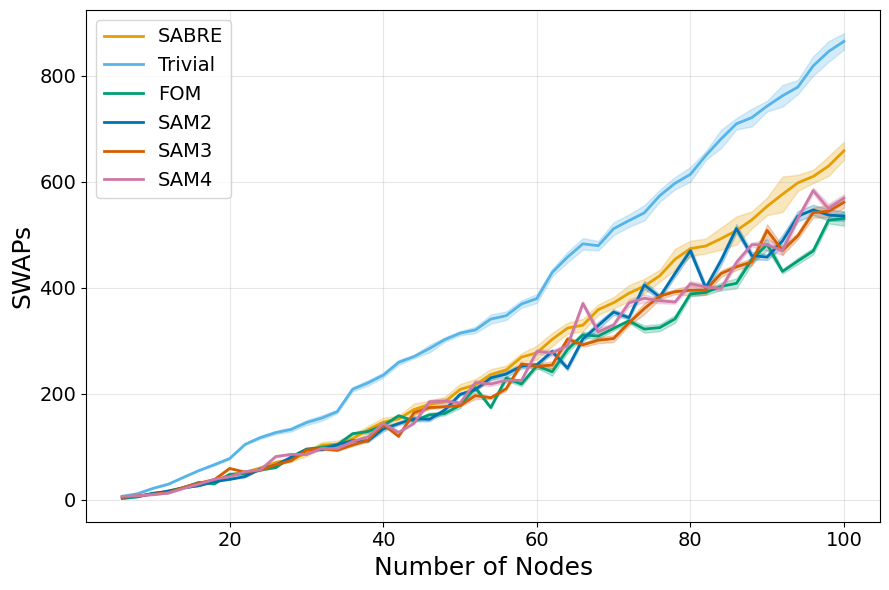

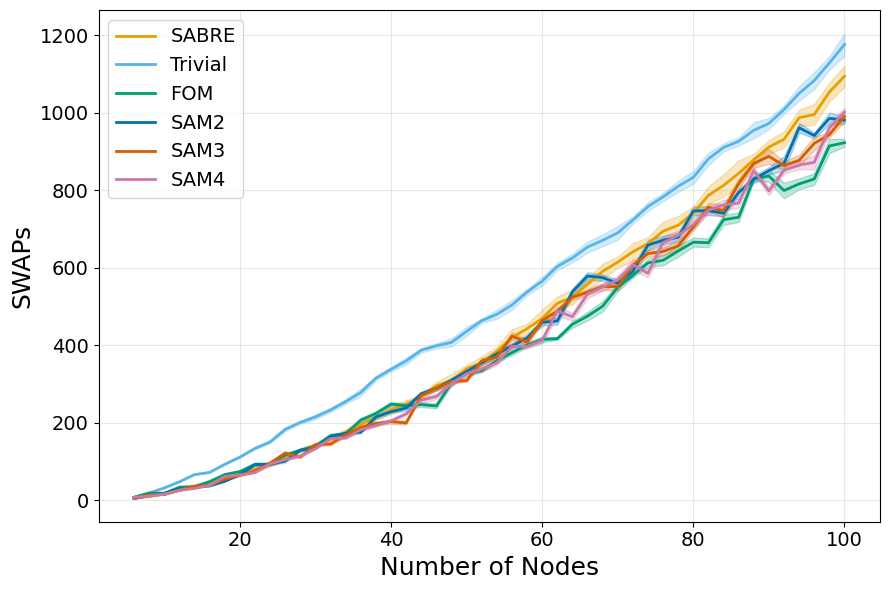

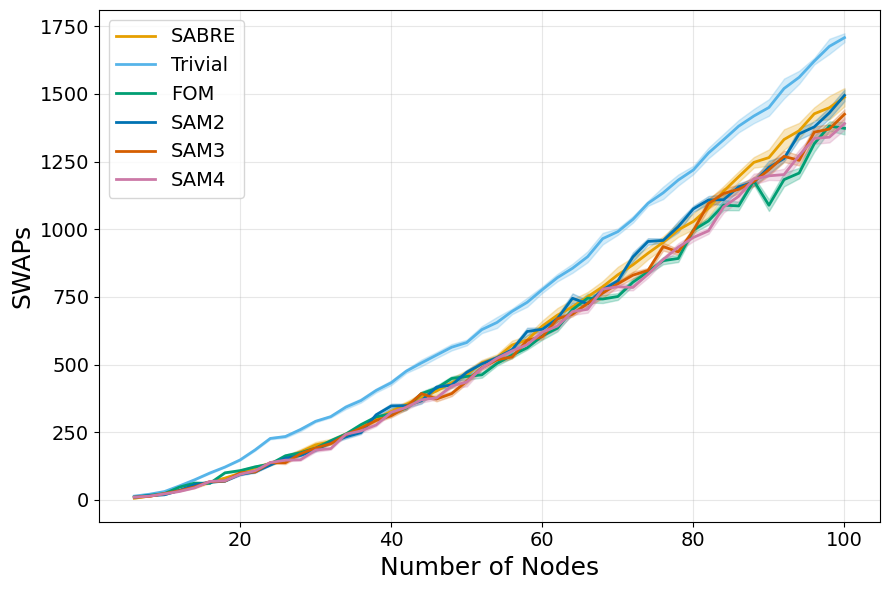

In [15]:
plot_swap_results(swaps_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="SWAPs")

2Q GATES

In [16]:
import matplotlib.pyplot as plt

nodes_reg = list(range(10, 101, 2))
params_reg = list(range(3,9,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
twoq_reg={}
for param in params_reg:
    twoq_reg[param] = return_ops_all_methods(backend, graph_type='reg', param=param,
                         average_over=10, node_list=nodes_reg, k_list=[2,3,4],
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=1, reps=1, noise_aware=True)

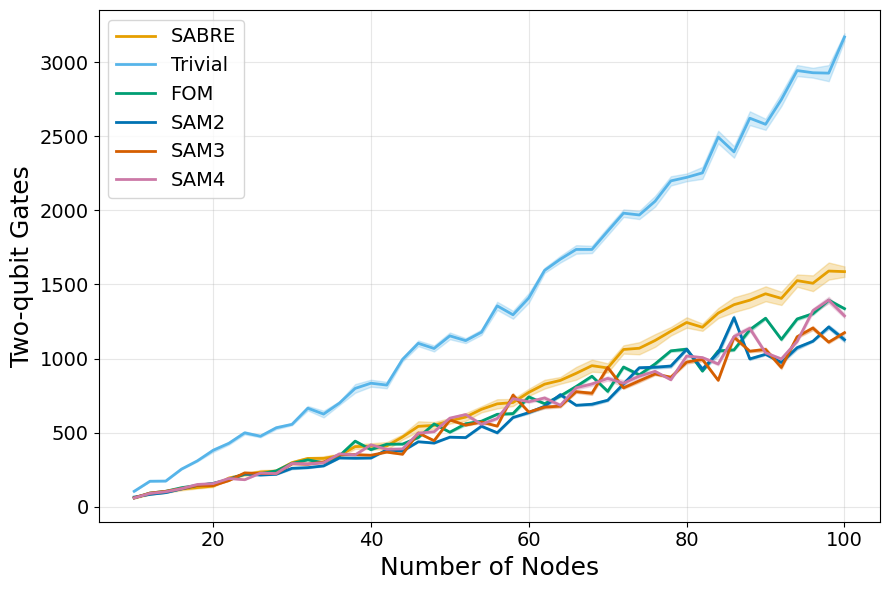

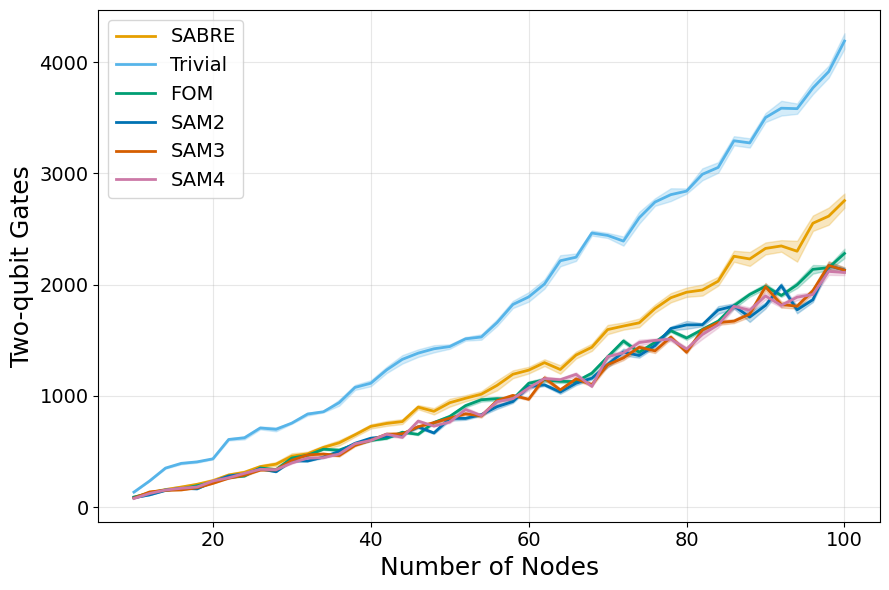

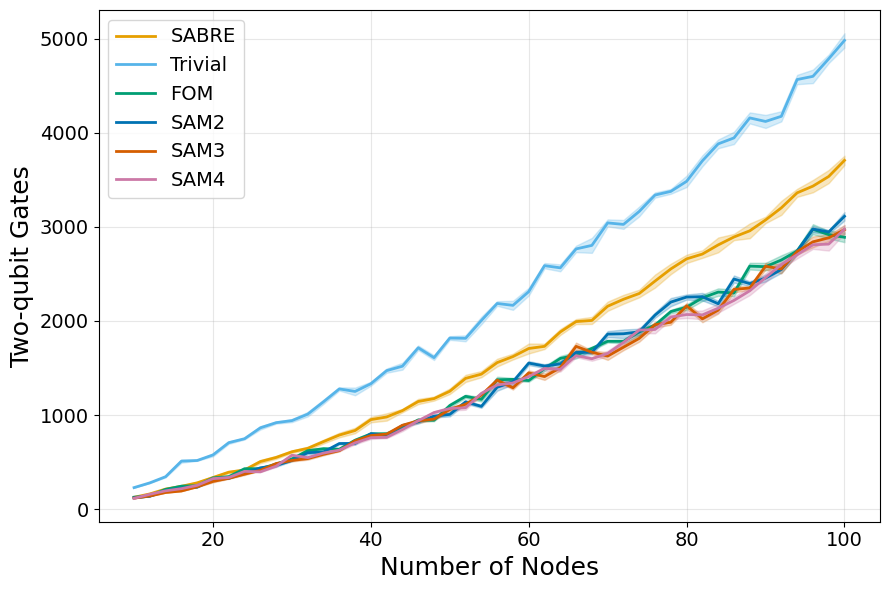

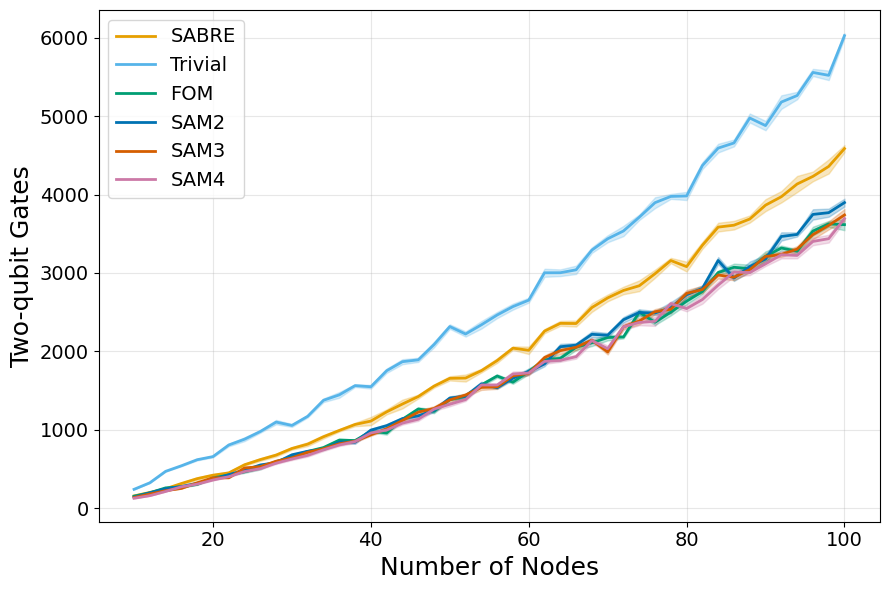

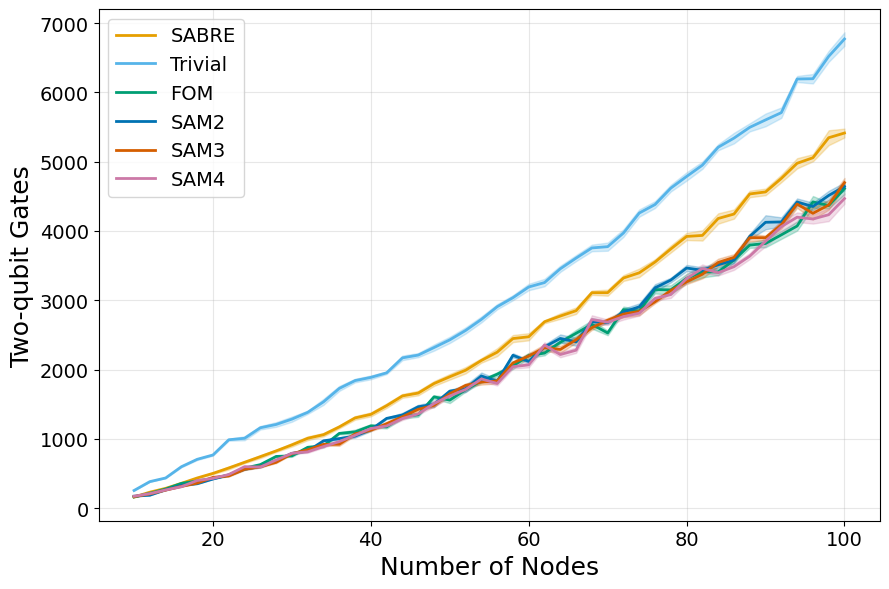

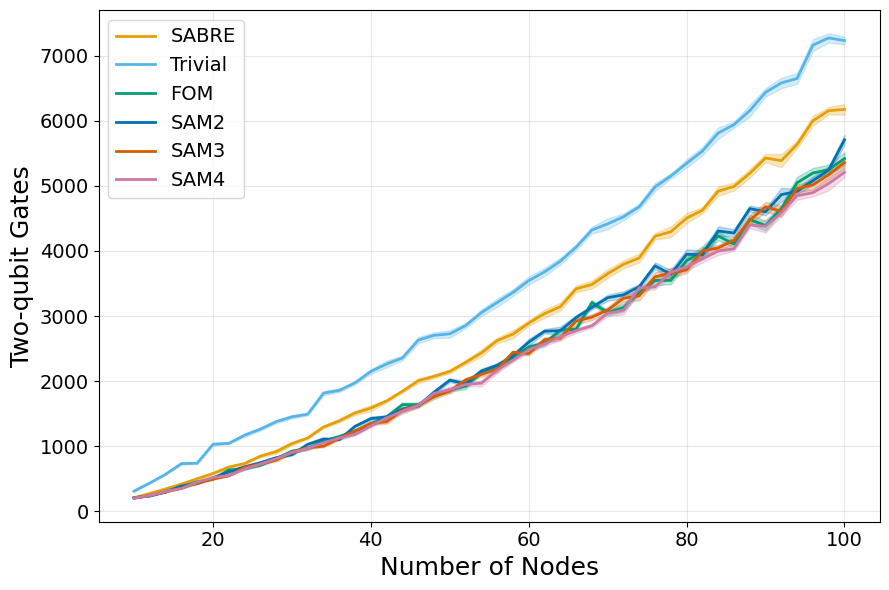

In [17]:
plot_swap_results(twoq_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="Two-qubit Gates")

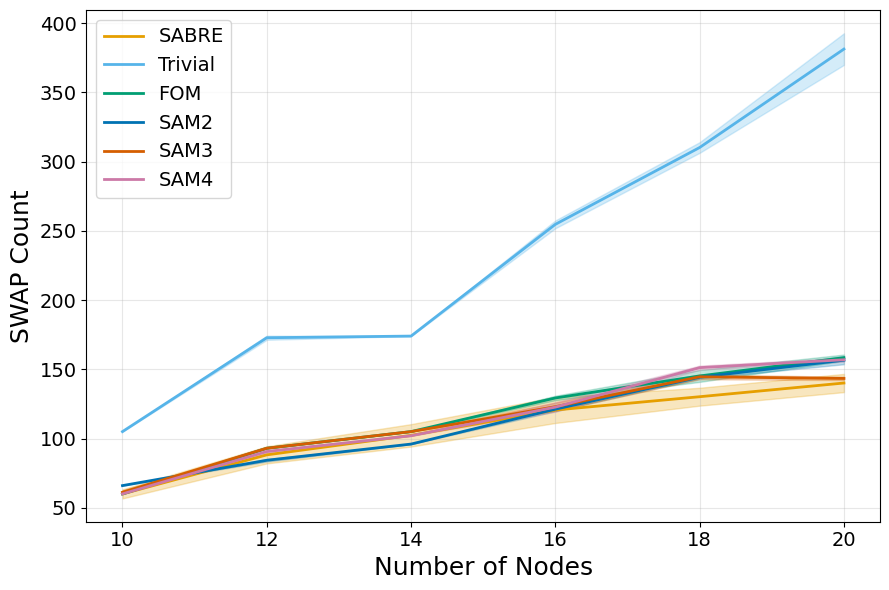

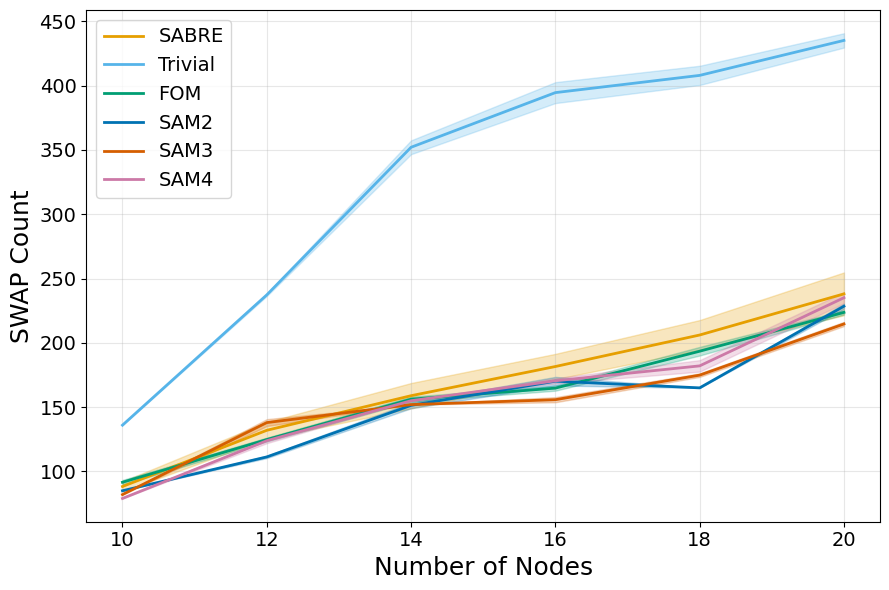

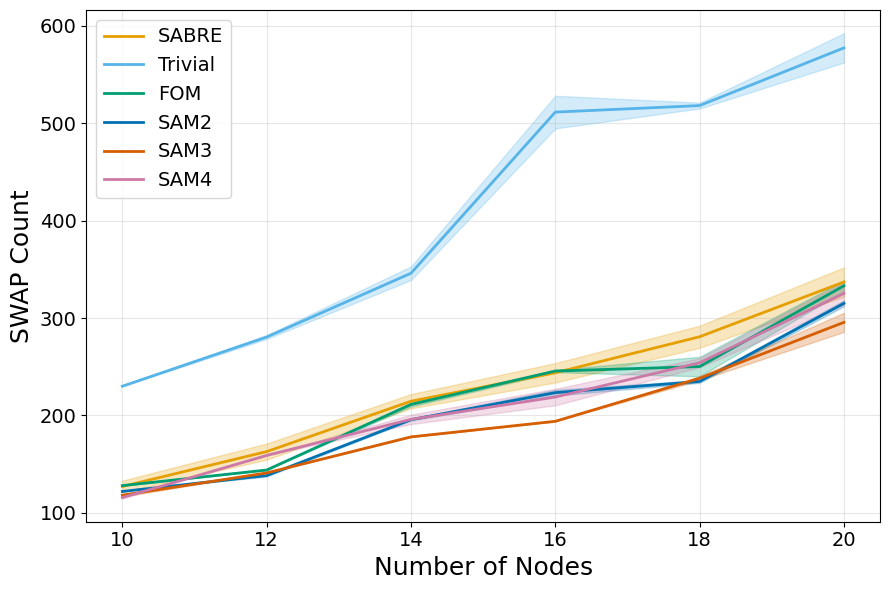

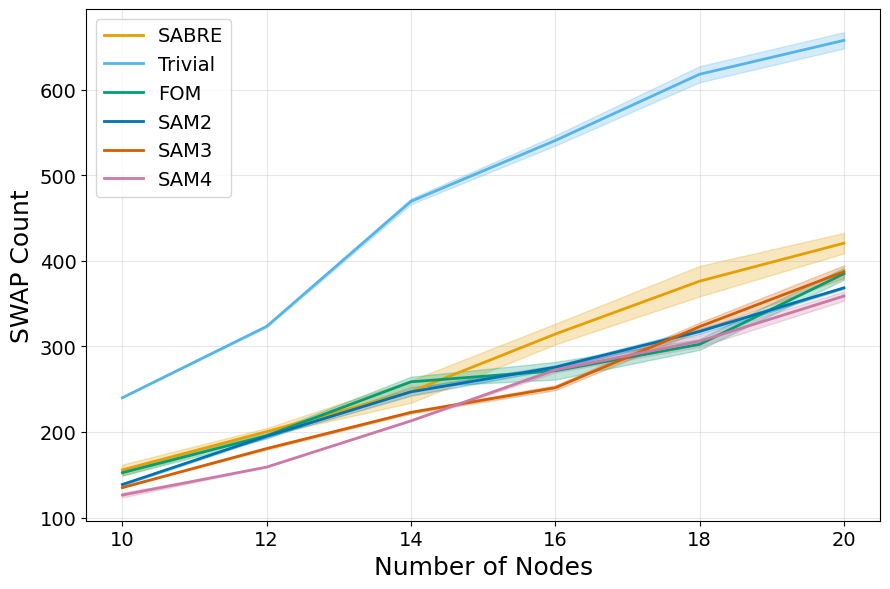

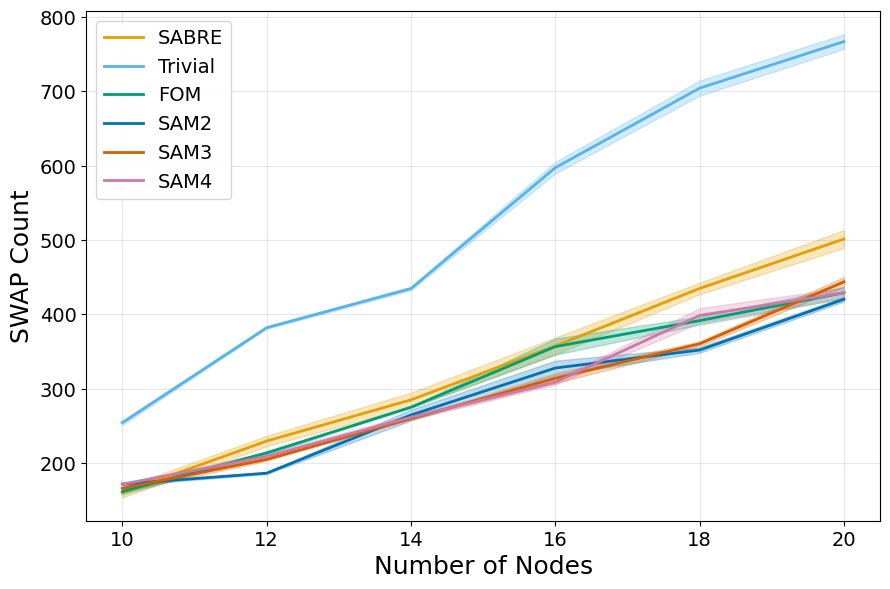

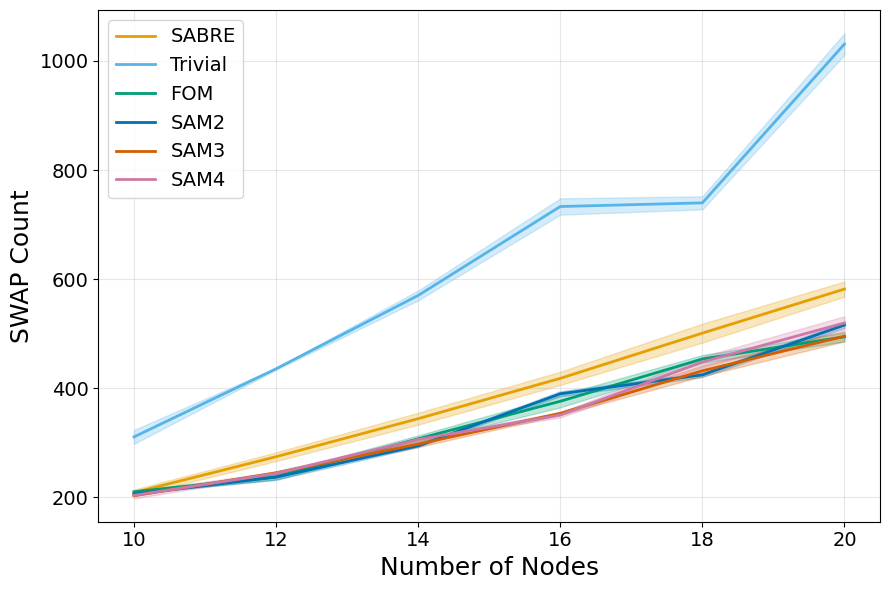

In [18]:
plot_swap_results(twoq_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, zoom=6)

In [19]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
twoq_ba={}
for param in params_ba:
    twoq_ba[param] = return_ops_all_methods(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba, k_list=[2,3,4],
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=1, reps=1, noise_aware=True, stop_after_routing=False)

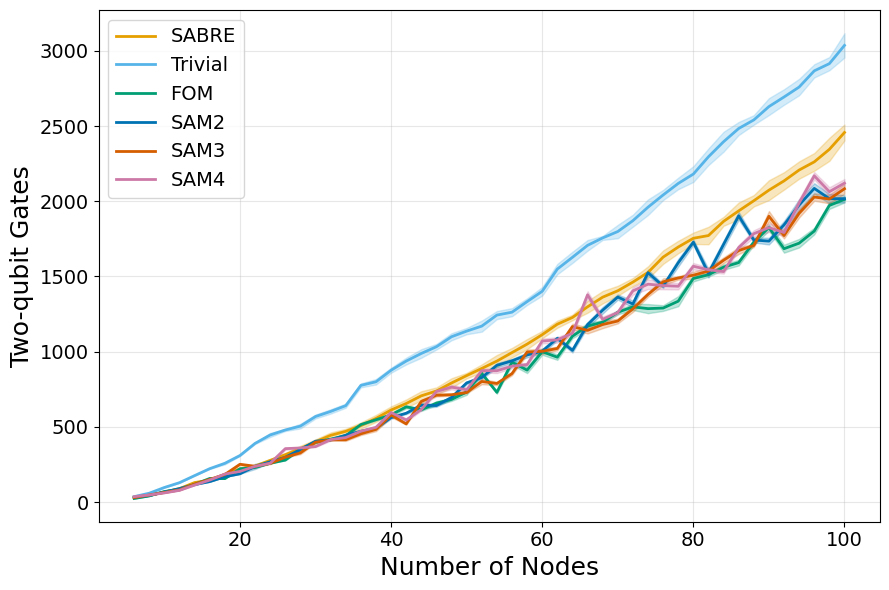

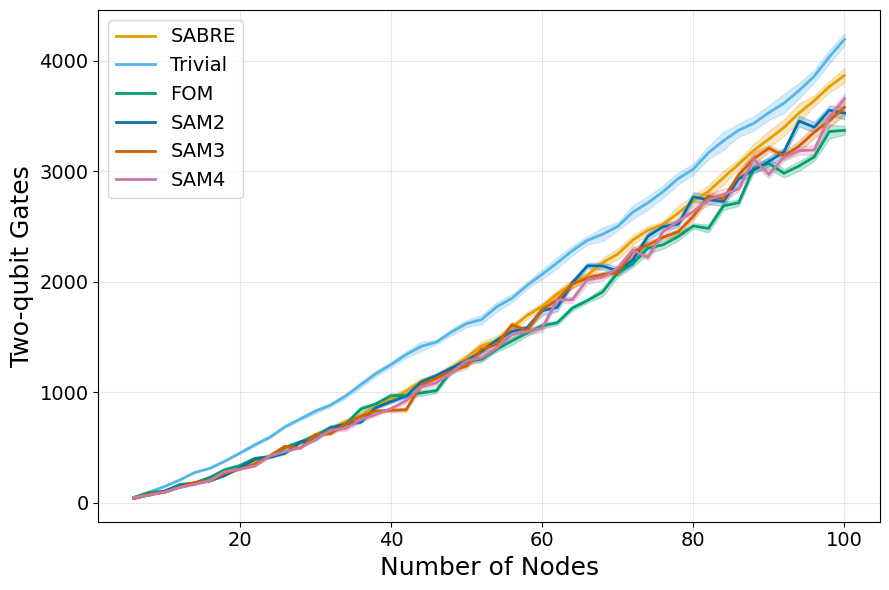

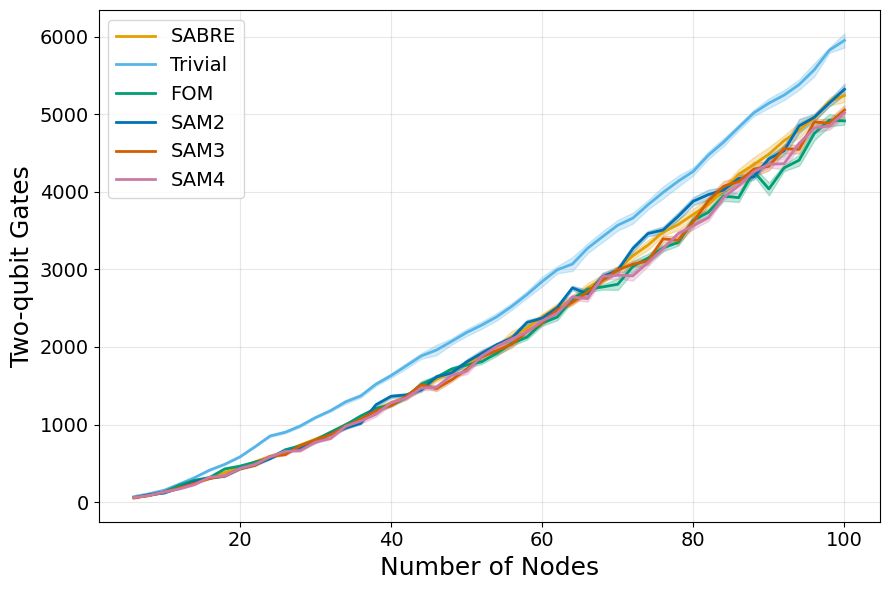

In [20]:
plot_swap_results(twoq_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="Two-qubit Gates")

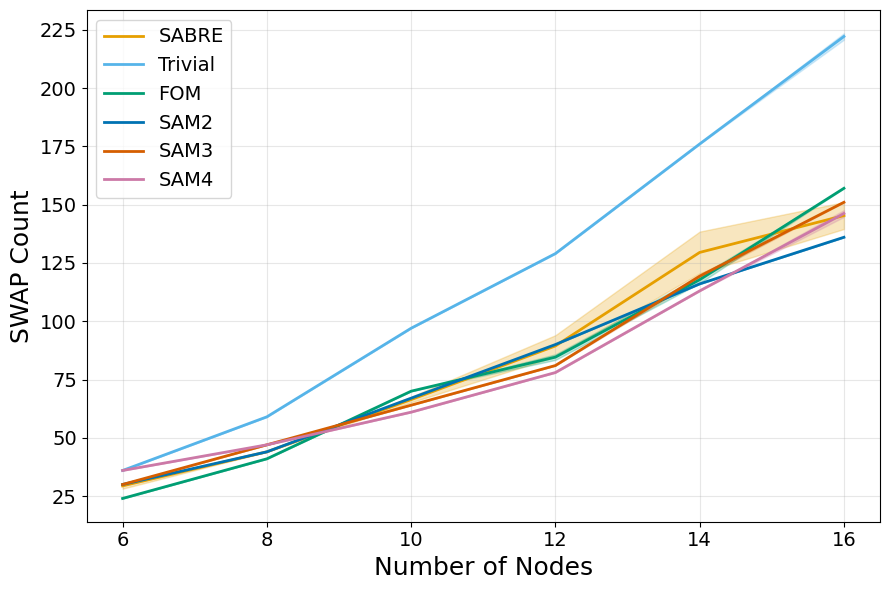

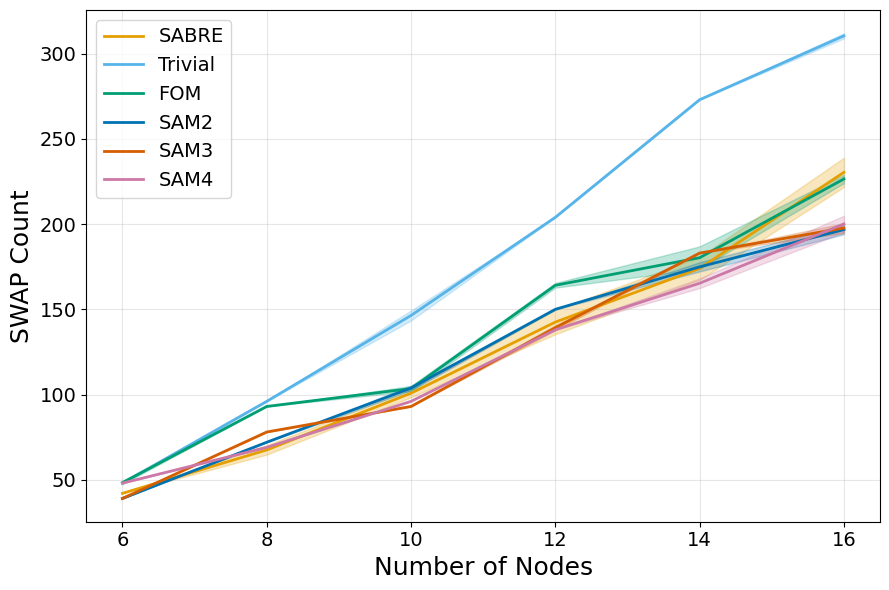

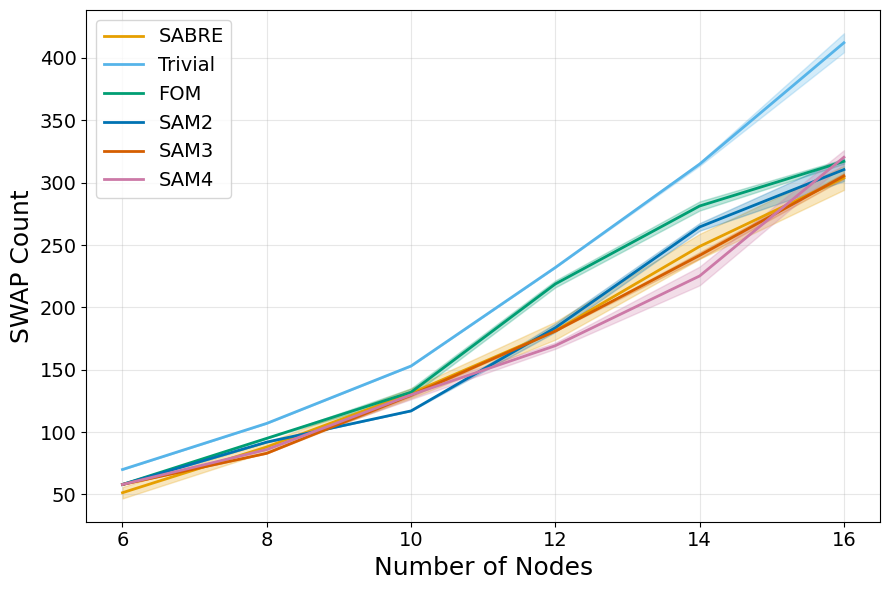

In [21]:
plot_swap_results(twoq_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, zoom=6)

In [23]:
swap_imp_reg = compute_all_improvements(swaps_reg, k_list=[2,3,4], baseline="SABRE")
swap_imp_ba = compute_all_improvements(swaps_ba, k_list=[2,3,4], baseline="SABRE")

twoq_imp_reg = compute_all_improvements(twoq_reg, k_list=[2,3,4], baseline="SABRE")
twoq_imp_ba = compute_all_improvements(twoq_ba, k_list=[2,3,4], baseline="SABRE")

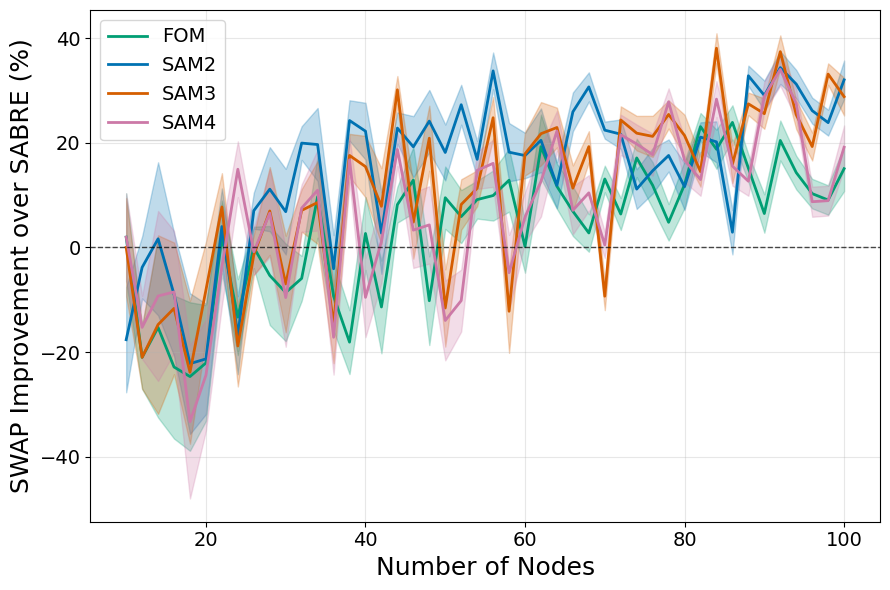

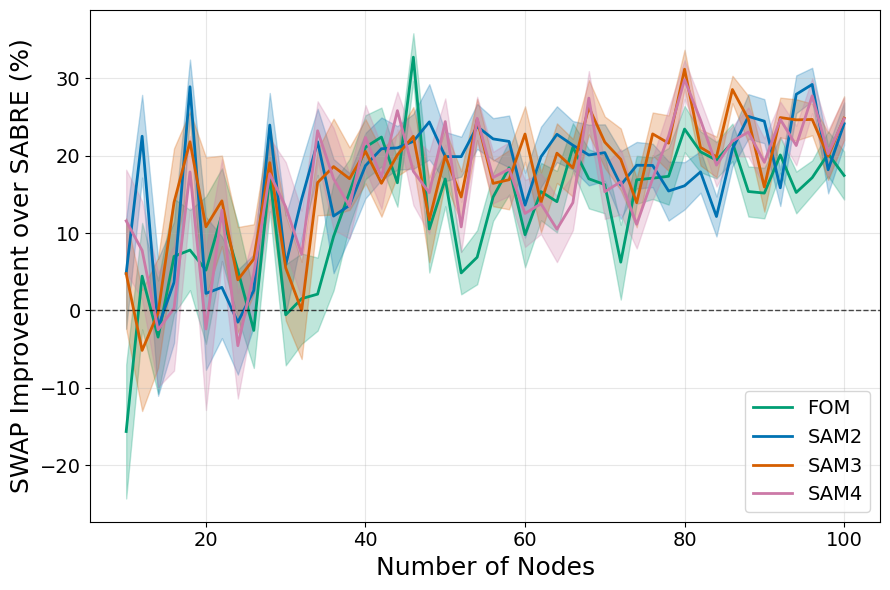

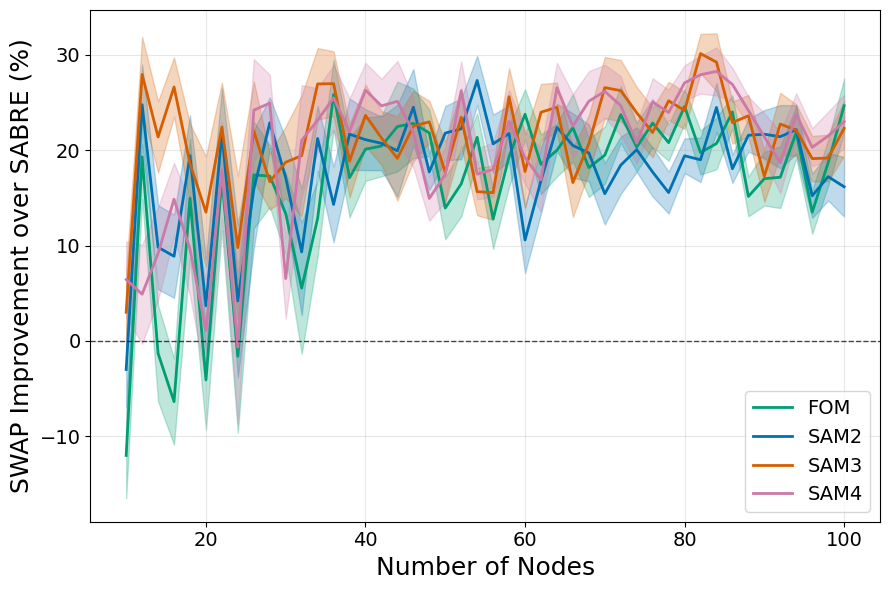

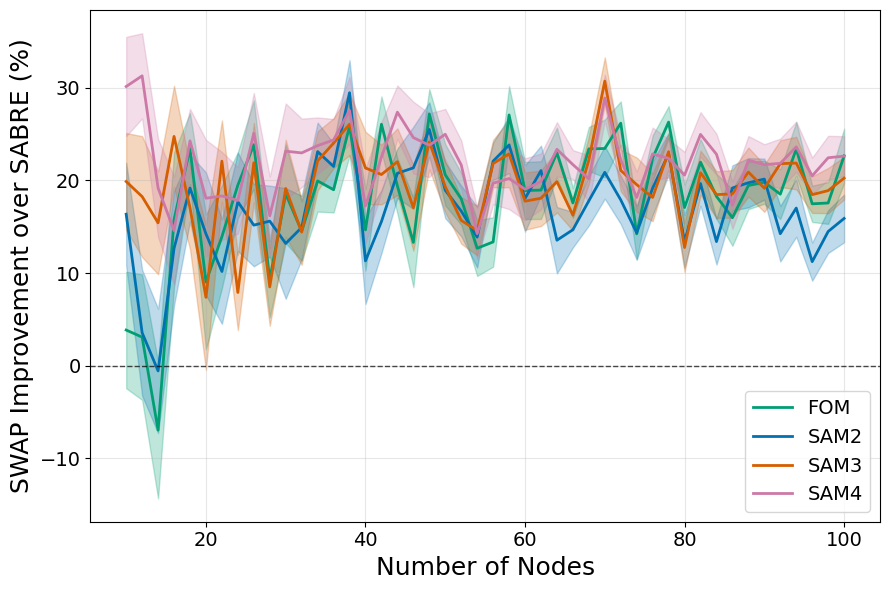

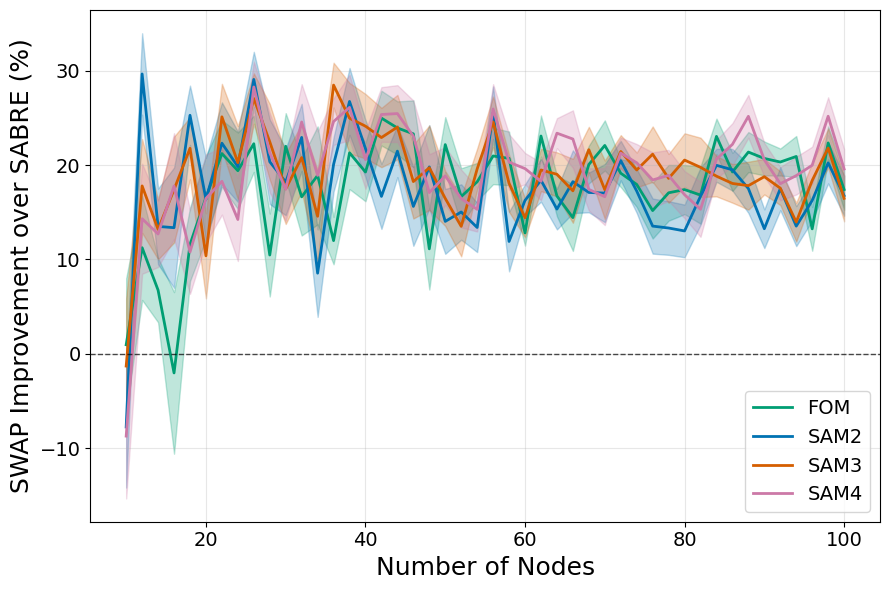

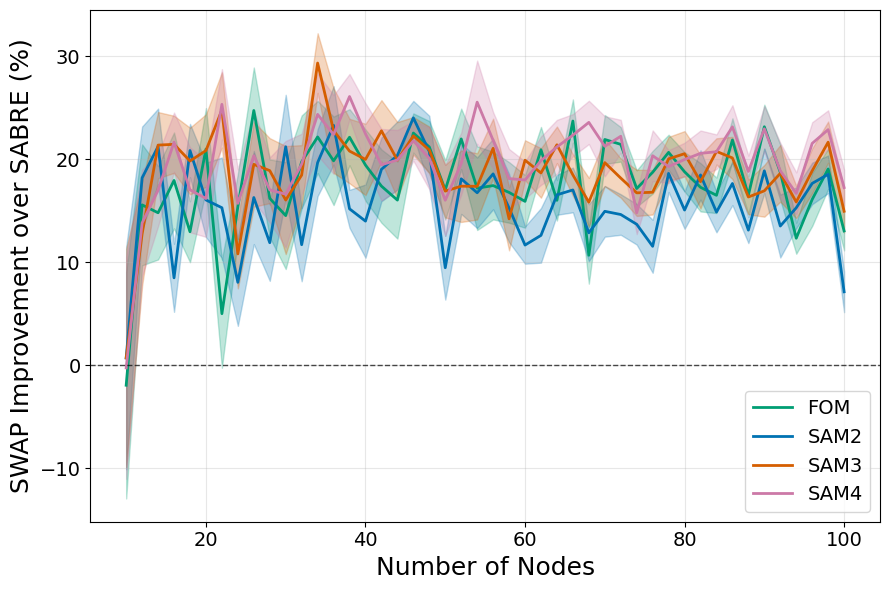

In [24]:
plot_percentage_improvements(swap_imp_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="SWAP Improvement over SABRE (%)")


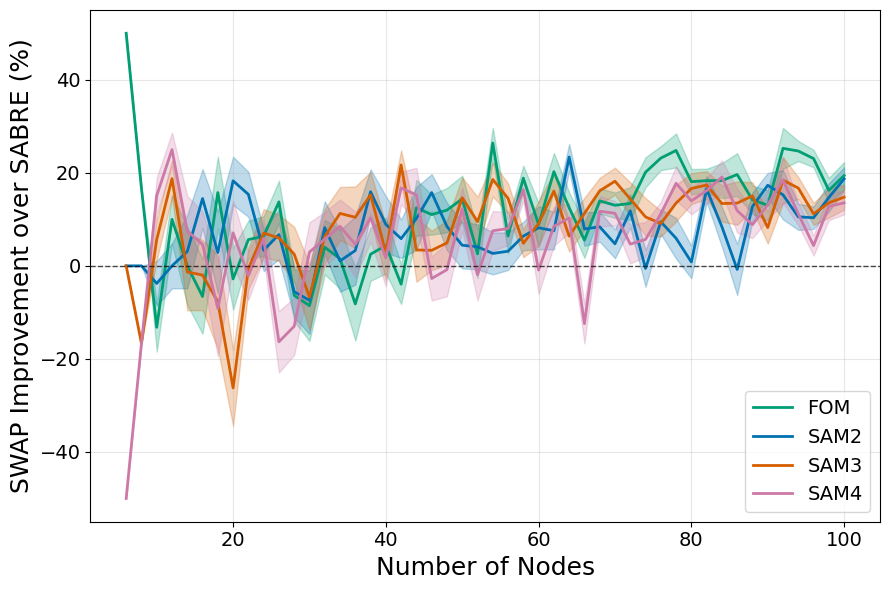

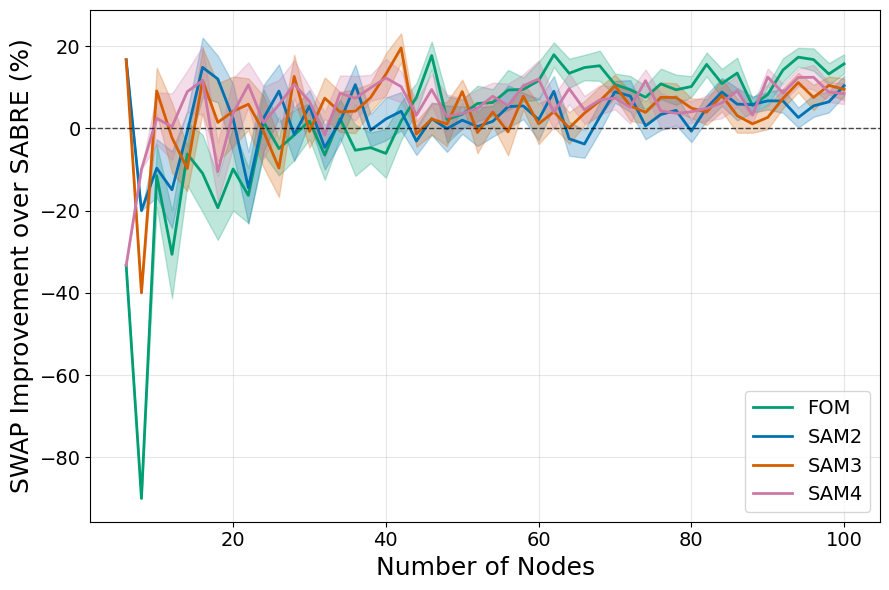

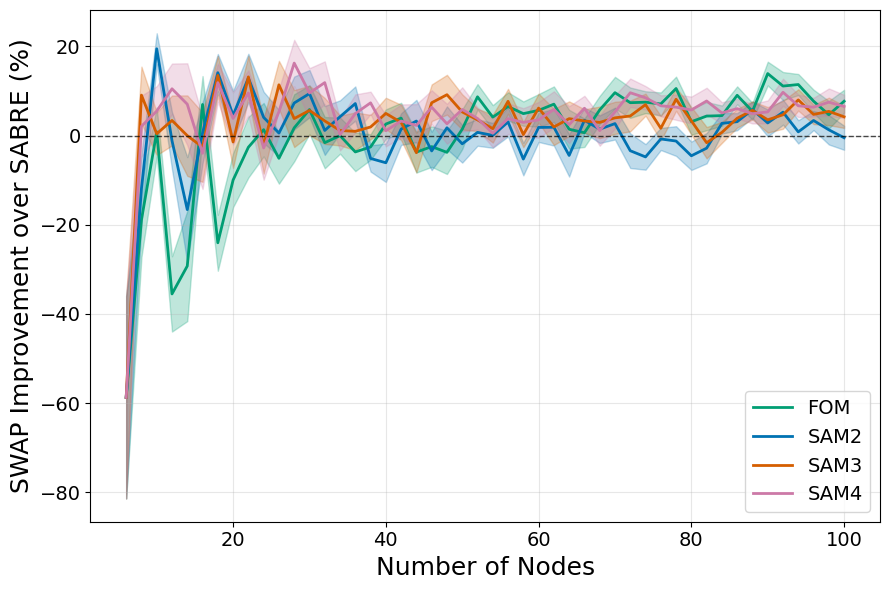

In [25]:
plot_percentage_improvements(swap_imp_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="SWAP Improvement over SABRE (%)")


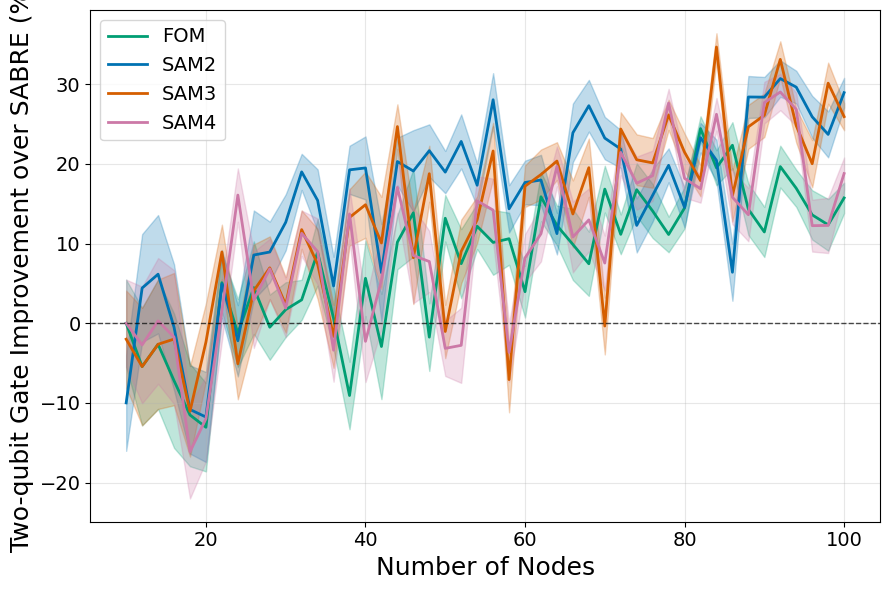

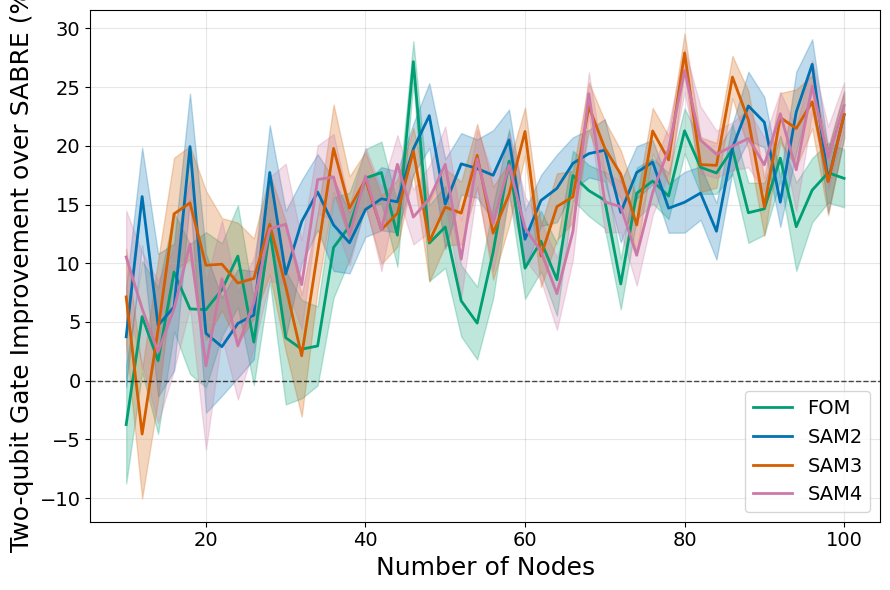

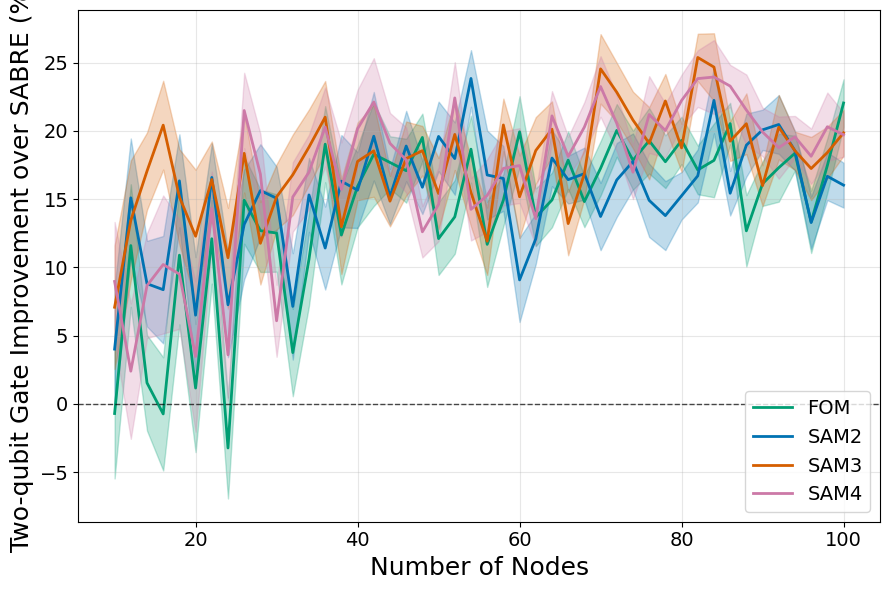

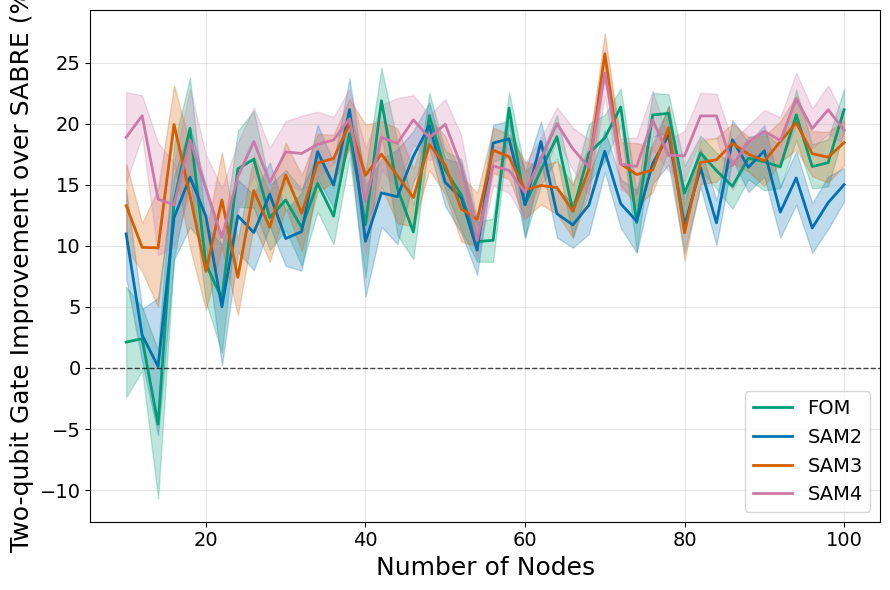

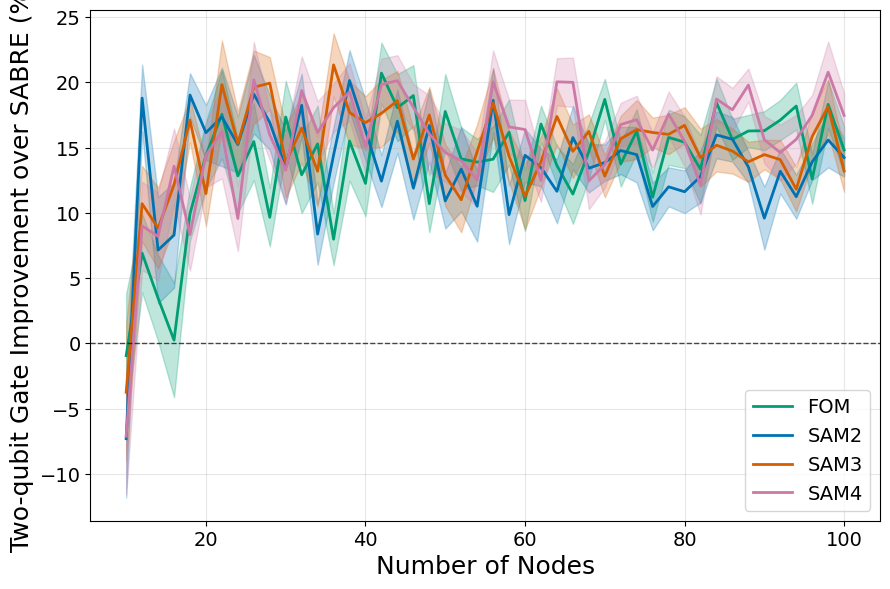

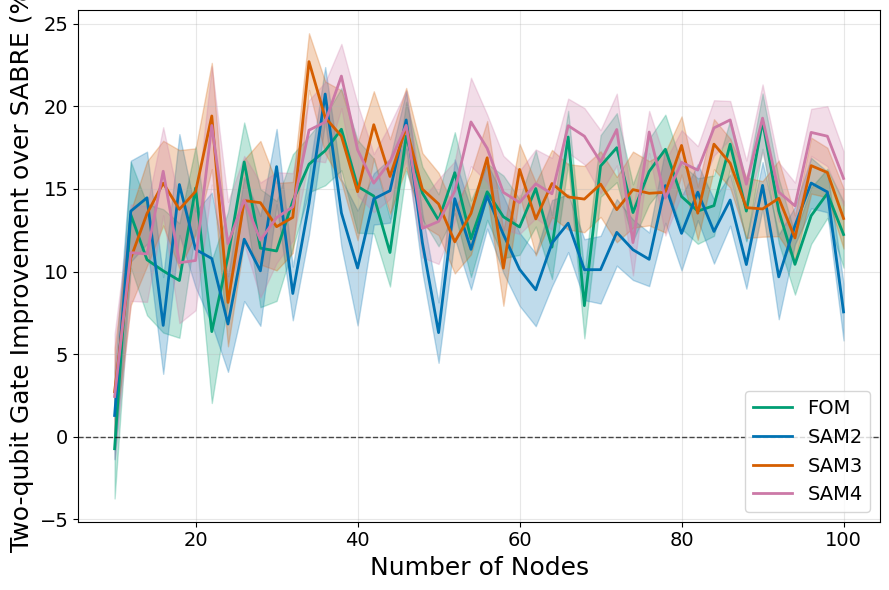

In [26]:
plot_percentage_improvements(twoq_imp_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="Two-qubit Gate Improvement over SABRE (%)")


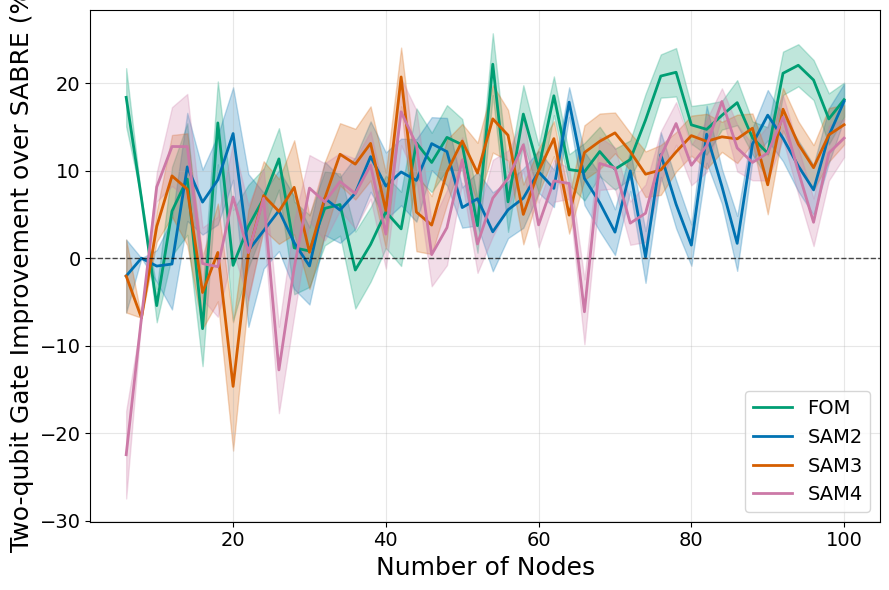

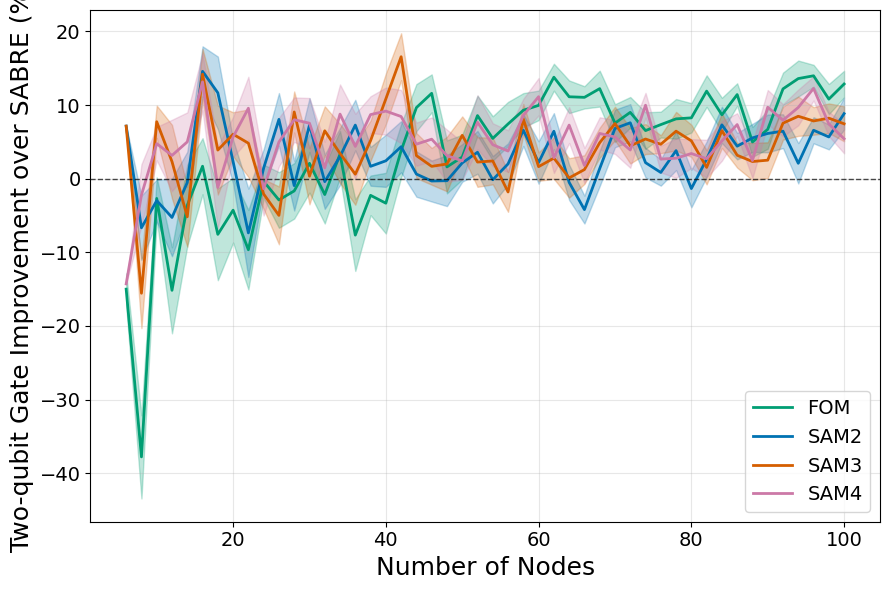

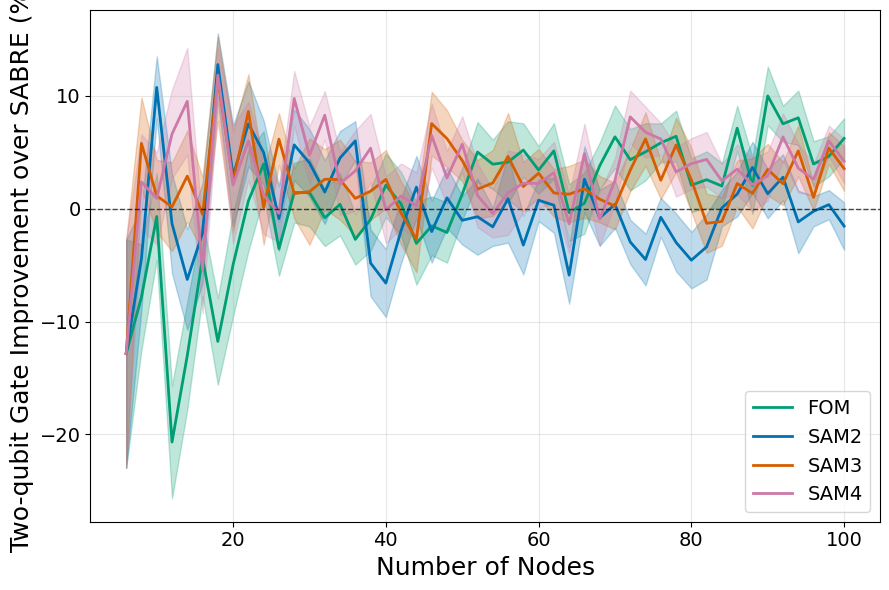

In [27]:
plot_percentage_improvements(twoq_imp_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="Two-qubit Gate Improvement over SABRE (%)")